# 06 · Experiment log: every model and every build, side by side

Every evaluation run is recorded in **`eval/experiment_log.csv`**: one row per *build* (a version of the code, knowledge base and question set) and *configuration* (model, with or without the course, retriever, ablation). Nothing is overwritten: a new model or a new version adds rows.

Each row records:
- **what was run:** build, git commit, knowledge-base size, a hash of the question set, the Ollama model digest
- **how it scored:** the automatic metrics, plus the hand-checked score where we re-read the answers (`eval/hand_labels.json`)

How a run gets logged:
- `./scripts/run_evaluation.sh` logs itself at the end (set `BUILD="name"` to name it).
- Any folder of results can be logged by hand: `uv run python -m study_assistant.experiment_log --build "my build" --results eval/results`

This notebook only reads the log, so it runs anywhere, without Ollama or API keys.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from math import sqrt
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
from study_assistant.experiment_log import load_log

log = load_log()
BUILDS = list(dict.fromkeys(log.build))  # in the order they were logged

def label(r):
    """Readable name for a configuration."""
    model = {"llama3.1:8b": "Llama 3.1 8B", "google/flan-t5-base": "flan-t5"}.get(r.model, r.model)
    if r.system == "no_rag":
        return f"{model}, no course" + {"": "", "syllabus": ", sees syllabus (strict)",
                                         "syllabus-lenient": ", sees syllabus (lenient)"}.get(r.variant, f", {r.variant}")
    extra = {"": "", "nograde": " · relevance check off", "verify": " · support check (strict)",
             "verify-concept": " · support check (concept)", "nofloor": " · similarity floor off",
             "ctx-small": " · less context (3 passages)", "ctx-large": " · more context (8 passages)"
             }.get(r.variant, f" · {r.variant}")
    return f"{model} + course ({r.retriever}){extra}"

log["config"] = log.apply(label, axis=1)
log[["build", "commit", "kb_documents", "questions_hash", "config", "correct_main", "correct_hand", "correct_hand_strict",
     "not_covered_declined", "sec_per_question"]]

,build,commit,kb_documents,questions_hash,config,correct_main,correct_hand,correct_hand_strict,not_covered_declined,sec_per_question
0,before audit (Step 5),f1adc5a,507,271793dd,"flan-t5, no course",0.000,NaN,NaN,0.583,1.400
1,before audit (Step 5),f1adc5a,507,271793dd,"Llama 3.1 8B, no course",0.553,NaN,NaN,0.333,7.257
2,before audit (Step 5),f1adc5a,507,271793dd,flan-t5 + course (dense),0.316,NaN,NaN,0.667,0.979
3,before audit (Step 5),f1adc5a,507,271793dd,Llama 3.1 8B + course (dense),0.816,NaN,NaN,0.833,12.987
4,before audit (Step 5),f1adc5a,507,271793dd,Llama 3.1 8B + course (hybrid),0.974,NaN,NaN,0.917,13.917
5,after audit (final),91cc6b3,538,25e37c66,"flan-t5, no course",0.000,NaN,NaN,0.500,0.200
6,after audit (final),91cc6b3,538,25e37c66,"Llama 3.1 8B, no course",0.474,0.605,0.605,0.333,7.121
7,after audit (final),91cc6b3,538,25e37c66,flan-t5 + course (hybrid),0.237,NaN,NaN,0.667,0.844
8,after audit (final),91cc6b3,538,25e37c66,Llama 3.1 8B + course (dense),0.789,0.921,0.868,0.917,13.372
9,after audit (final),91cc6b3,538,25e37c66,Llama 3.1 8B + course (hybrid),0.947,0.974,0.921,1.000,13.738


**How to read the columns**
- **correct_main**: the automatic metric. It counts an answer as correct when the grader (Llama 3.1 8B with course excerpts) says so *and* at least half the key facts are present.
- **correct_hand**: the same after re-reading answers by hand. It is blank where we didn't hand-check.
- **correct_hand_strict**: the same, but answers we gave the benefit of the doubt (borderline) count as wrong.
- **not_covered_declined**: the share of the 12 not-covered questions where the system said "not covered".
- **questions_hash** changes when the question set changes, so two builds with different hashes were not scored on identical questions.

## 1. The final build: every configuration

Correctness on the 38 covered questions, with 95% Wilson intervals: the hand-checked score where we have one (filled dot), otherwise the automatic one (hollow dot). Next to it, the share of the 12 not-covered questions declined.

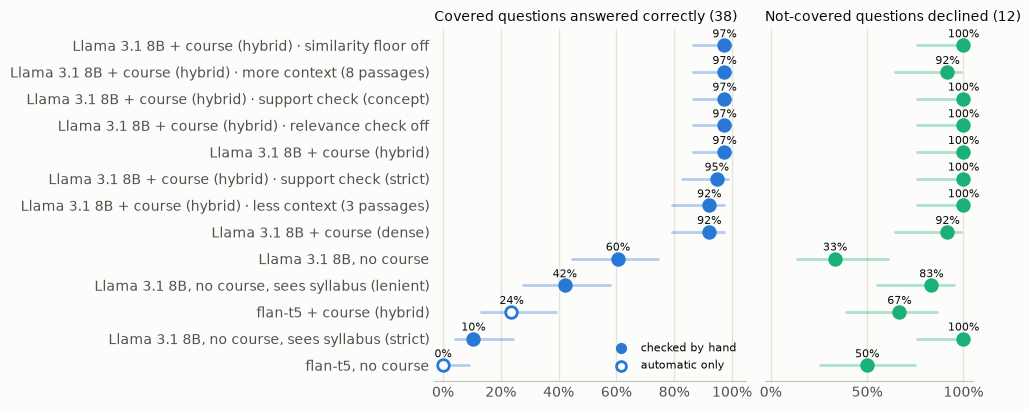

In [2]:
def wilson(p, n, z=1.96):
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0, c - h), min(1, c + h)

final = log[log.build == BUILDS[-1]].copy()
final["correct"] = final.correct_hand.fillna(final.correct_main)
final["checked"] = final.correct_hand.notna()
final = final.sort_values("correct")

BLUE, GREEN, INK, MUTED, GRID, BG = "#2a78d6", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3dc", "#fcfcfb"
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
for y, r in enumerate(final.itertuples()):
    lo, hi = wilson(r.correct, r.n_answerable)
    a1.plot([lo, hi], [y, y], color=BLUE, lw=2, alpha=0.35, solid_capstyle="round")
    a1.scatter(r.correct, y, s=70, color=BLUE if r.checked else BG, edgecolor=BLUE, lw=2, zorder=3)
    a1.text(r.correct, y + 0.3, f"{r.correct:.0%}", ha="center", fontsize=8, color=INK)
    lo, hi = wilson(r.not_covered_declined, r.n_not_covered)
    a2.plot([lo, hi], [y, y], color=GREEN, lw=2, alpha=0.35, solid_capstyle="round")
    a2.scatter(r.not_covered_declined, y, s=70, color=GREEN, edgecolor=GREEN, lw=2, zorder=3)
    a2.text(r.not_covered_declined, y + 0.3, f"{r.not_covered_declined:.0%}", ha="center", fontsize=8, color=INK)
a1.set_yticks(range(len(final)), final.config)
a1.set_title("Covered questions answered correctly (38)", loc="left", fontsize=10, color=INK)
a2.set_title("Not-covered questions declined (12)", loc="left", fontsize=10, color=INK)
for a in (a1, a2):
    a.set_xlim(-0.03, 1.05); a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    a.grid(axis="x", color=GRID, lw=1); a.set_axisbelow(True); a.set_facecolor(BG)
    for s in ("top", "right", "left"): a.spines[s].set_visible(False)
    a.spines["bottom"].set_color("#c3c2b7"); a.tick_params(colors=MUTED, length=0)
a1.scatter([], [], s=50, color=BLUE, label="checked by hand"); a1.scatter([], [], s=50, color=BG, edgecolor=BLUE, lw=2, label="automatic only")
a1.legend(frameon=False, fontsize=8, loc="lower right")
fig.patch.set_facecolor(BG); plt.tight_layout(); plt.show()

- **The course is what matters:** every configuration with the course (Llama) scores far above the same model without it. The intervals don't overlap.
- **Among the Llama + course variants the intervals overlap heavily.** 38 questions can't separate hybrid from dense, or tell whether the relevance or support checks help (paired tests in notebook 05).
- **flan-t5 is not usable here,** with or without the course.

## 2. Quality vs speed

What each configuration costs per question on the laptop (M2, local models), against how often it is right.

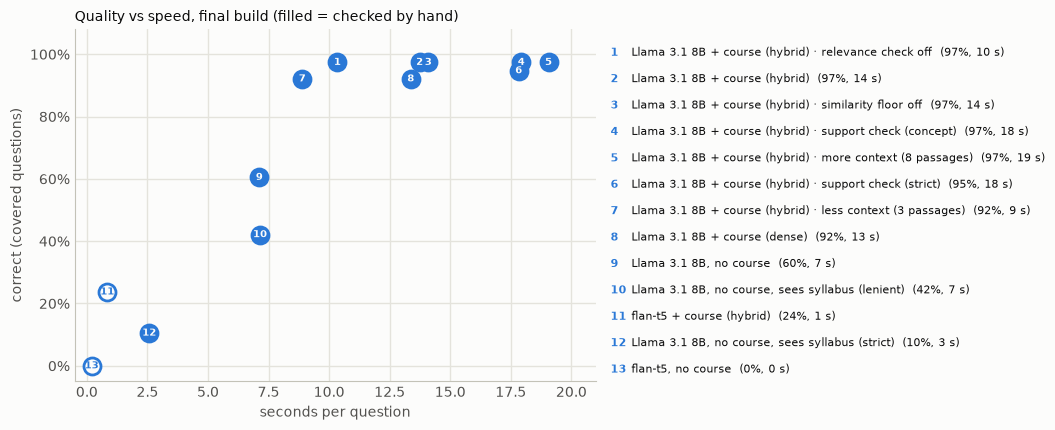

In [3]:
pts = final.sort_values(["correct", "sec_per_question"], ascending=[False, True]).reset_index(drop=True)
fig, (ax, key) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [3, 2]})
for n, r in enumerate(pts.itertuples(), start=1):
    ax.scatter(r.sec_per_question, r.correct, s=150, color=BLUE if r.checked else BG, edgecolor=BLUE, lw=2, zorder=3)
    ax.text(r.sec_per_question, r.correct, str(n), ha="center", va="center", fontsize=7,
            color=BG if r.checked else BLUE, zorder=4, fontweight="bold")
    key.text(0, 1 - n * 0.075, f"{n}", fontsize=8, color=BLUE, fontweight="bold", transform=key.transAxes)
    key.text(0.06, 1 - n * 0.075, f"{r.config}  ({r.correct:.0%}, {r.sec_per_question:.0f} s)", fontsize=8,
             color=INK, transform=key.transAxes)
key.axis("off")
ax.set_xlabel("seconds per question", color=MUTED); ax.set_ylabel("correct (covered questions)", color=MUTED)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_ylim(-0.05, 1.08); ax.set_xlim(-0.5, 21)
ax.grid(color=GRID, lw=1); ax.set_axisbelow(True); ax.set_facecolor(BG)
for s in ("top", "right"): ax.spines[s].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("#c3c2b7")
ax.tick_params(colors=MUTED, length=0)
ax.set_title("Quality vs speed, final build (filled = checked by hand)", loc="left", fontsize=10, color=INK)
fig.patch.set_facecolor(BG); plt.tight_layout(); plt.show()

- The course roughly **doubles the time per answer** (7 s → 14 s), mostly because the prompt is longer. The relevance check costs about 3.5 s, the support check about 4 s, and showing 8 passages instead of 5 about 5 s.
- **Turning the relevance check off is the fastest configuration with full accuracy** on this set (notebook 05, section 6, explains why it stays in the code). Showing only 3 passages is faster still but loses accuracy.
- **Giving the plain model the syllabus doesn't help:** with either wording it stays far below the assistant (see notebook 05, section 8).

## 3. Builds over time: before and after the audit

The same five configurations, scored by the Step 5 build and by the final build. Between them we added a missing lecture deck (507 → 538 documents), replaced one mislabelled question, tightened the key facts and fixed the scoring. **The question sets differ** (different `questions_hash`), so this shows how the *measurement* changed as much as the system.

Both builds are shown on the automatic metric, the only one that exists for both.

correct_main                      not_covered_declined                    
build                          before audit (Step 5) after audit (final) before audit (Step 5) after audit (final)
key                                                                                                               
flan-t5, no course                             0.000               0.000                 0.583               0.500
Llama 3.1 8B, no course                        0.553               0.474                 0.333               0.333
flan-t5 + course (…)                           0.316               0.237                 0.667               0.667
Llama 3.1 8B + course (dense)                  0.816               0.789                 0.833               0.917
Llama 3.1 8B + course (hybrid)                 0.974               0.947                 0.917               1.000

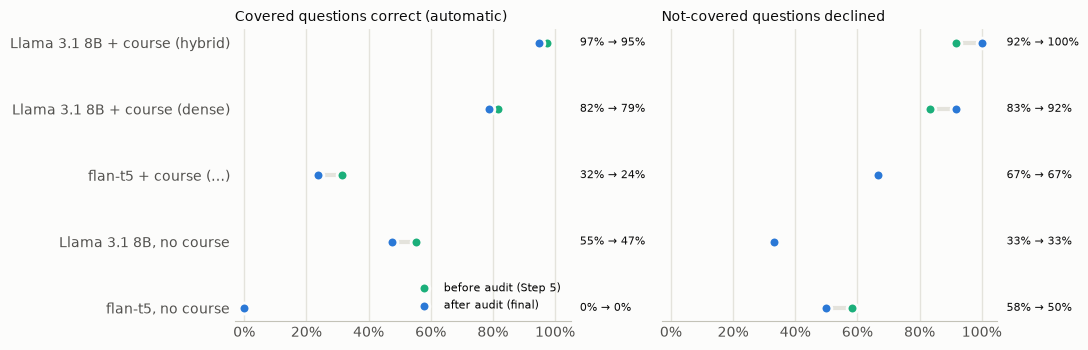

In [4]:
def same_config(c):  # flan-t5 + course was run with dense retrieval before the audit and hybrid after
    return c.replace("(dense)", "(…)").replace("(hybrid)", "(…)") if c.startswith("flan") else c

log["key"] = log.config.map(same_config)
common = [k for k in log[log.build == BUILDS[-1]].key if k in set(log[log.build == BUILDS[0]].key)]
pivot = {m: log[log.key.isin(common)].pivot_table(index="key", columns="build", values=m).loc[common, BUILDS]
         for m in ["correct_main", "not_covered_declined"]}
display(pd.concat(pivot, axis=1).round(3))

COLS = {BUILDS[0]: GREEN, BUILDS[-1]: BLUE}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
titles = {"correct_main": "Covered questions correct (automatic)", "not_covered_declined": "Not-covered questions declined"}
for ax, (m, t) in zip(axes, titles.items()):
    p = pivot[m]
    for y, k in enumerate(p.index):
        ax.plot(p.loc[k, BUILDS], [y, y], color=GRID, lw=3, zorder=1, solid_capstyle="round")
        for b in BUILDS:
            ax.scatter(p.loc[k, b], y, s=60, color=COLS[b], edgecolor=BG, lw=2, zorder=3, label=b if y == 0 else None)
        ax.text(1.08, y, f"{p.loc[k, BUILDS[0]]:.0%} → {p.loc[k, BUILDS[-1]]:.0%}", va="center", fontsize=8, color=INK)
    ax.set_title(t, loc="left", fontsize=10, color=INK); ax.set_xlim(-0.03, 1.05)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", color=GRID, lw=1); ax.set_axisbelow(True); ax.set_facecolor(BG)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7"); ax.tick_params(colors=MUTED, length=0)
axes[0].set_yticks(range(len(common)), common)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.patch.set_facecolor(BG); plt.tight_layout(); plt.show()

**Reading it**
- **The direction never changed:** in both builds the course beats no course by a wide margin.
- **The automatic correctness of most configurations went *down*** after the audit (hybrid 97% → 95%, no course 55% → 47%). That is the stricter key facts at work, not a worse system. The hand check (section 1) puts hybrid at 97%.
- **Declining not-covered questions went *up*** for Llama with the course (hybrid 92% → 100%, dense 83% → 92%). One reason is that the old "vanishing gradients" question, which the course partly covers, was replaced.
- This is why we log builds instead of overwriting results: without the "before" row, the "after" numbers can't be put in context.

## 4. Adding a new model

The code supports OpenAI and Gemini as well (`--backend openai|gemini`), but they haven't been evaluated yet: there is no Gemini key in `.env`, and OpenAI is paid. To add one to this log:

```bash
uv run python -m study_assistant.evaluation --backend gemini --systems rag,no_rag --out eval/runs/gemini
uv run python -m study_assistant.evaluation --out eval/runs/gemini --rejudge
uv run python -m study_assistant.experiment_log --build "after audit (final)" --results eval/runs/gemini
```

Logging under the existing build name adds the Gemini configurations to that build (each row keeps its own commit), so they appear in sections 1 and 2 next to Llama. Use a new build name instead when the code or questions changed. Then re-run this notebook.